In [1]:
import numpy as np
import scipy.stats as statty

import matplotlib.pyplot as plt

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

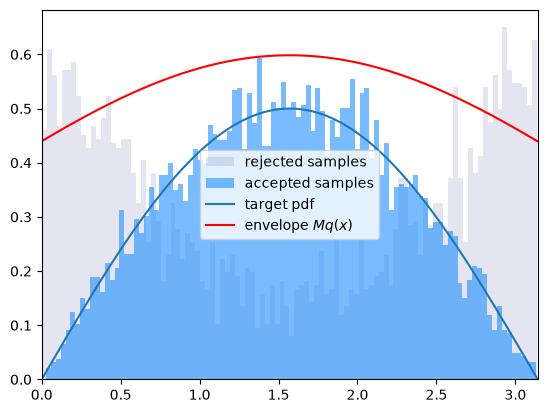

In [289]:

domain = np.arange(0, np.pi, step=np.pi/1000)

pdf = np.array([1/2*np.sin(i) for i in domain])

def target_pdf(x):
    return 0.5 * np.sin(x)


p_loc = np.mean(domain)

proposal = statty.norm(loc=p_loc, scale=2)


rng = np.random.default_rng(42)

def rejection_sampling(n, M, pdf_fn=pdf, prop_fn=proposal):
    
    n_accepted_samples = []
    n_rejected_samples = []

    #print(u, x, p)

    for _ in range(n):
        u = rng.uniform(0, 1)
        x = float(prop_fn.rvs())

        while not (domain[0] <= x <= domain[-1]):
            x = float(prop_fn.rvs())

        p = pdf_fn(x)

        if u < pdf_fn(x) / (M * prop_fn.pdf(x)):
            n_accepted_samples.append(x)
        else:
            n_rejected_samples.append(x)

    return (n_accepted_samples, n_rejected_samples)


samples, rejects = rejection_sampling(10000, 3, target_pdf, proposal)


fig, ax = plt.subplots()

ax.hist(rejects, bins=100, density=True, alpha=0.1, color="navy", label='rejected samples')
ax.hist(samples, bins=100, density=True, alpha=0.6, color="dodgerblue", label='accepted samples')
ax.plot(domain, target_pdf(domain), label="target pdf")
ax.plot(domain, M * proposal.pdf(domain), color="red", label=r"envelope $M q(x)$")


ax.set_xlim(0, np.pi)
ax.legend();

### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [2]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

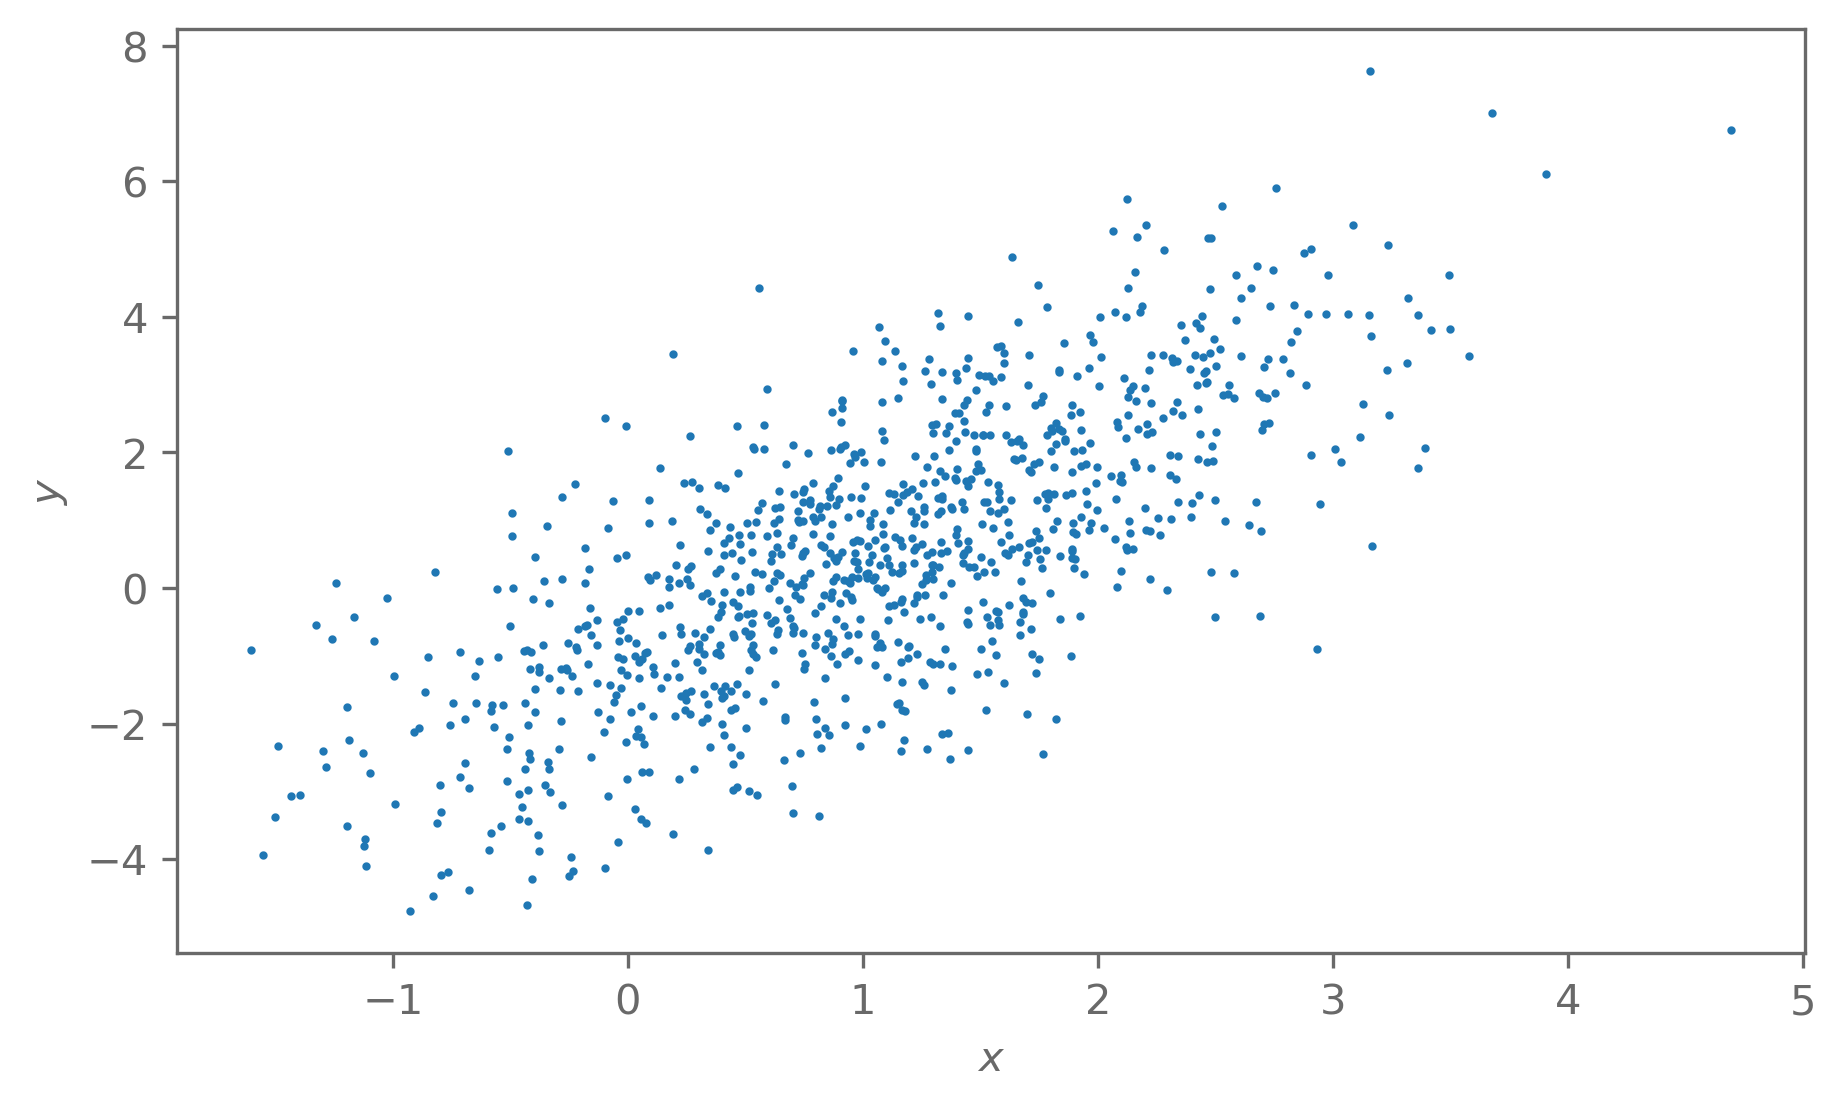

In [ ]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");